# ODE Exercises â€” Basics of Numerical Methods
Exercises from L. Bonaventura, ENHANCE, Lecco June-July 2026

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.linalg import expm

## Exercise 1
ODE: $y' = \frac{\alpha}{2}\cos(t)(1 - y^2)$, $t \in [0, 6\pi]$, $y(0) = 0$

Exact solution: $y(t) = \frac{e^{\alpha\sin t} - 1}{e^{\alpha\sin t} + 1}$

Methods: Explicit Euler, Leapfrog, `solve_ivp`. Cases: $\alpha=1$ and $\alpha=20$.

C:\Users\ismag\AppData\Local\Temp\ipykernel_28352\4144245893.py:2: RuntimeWarning: overflow encountered in scalar power
  return (alpha / 2) * np.cos(t) * (1 - y**2)
C:\Users\ismag\AppData\Local\Temp\ipykernel_28352\4144245893.py:25: RuntimeWarning: invalid value encountered in scalar add
  y[n + 1] = y[n - 1] + 2 * dt * f(t[n], y[n], alpha)


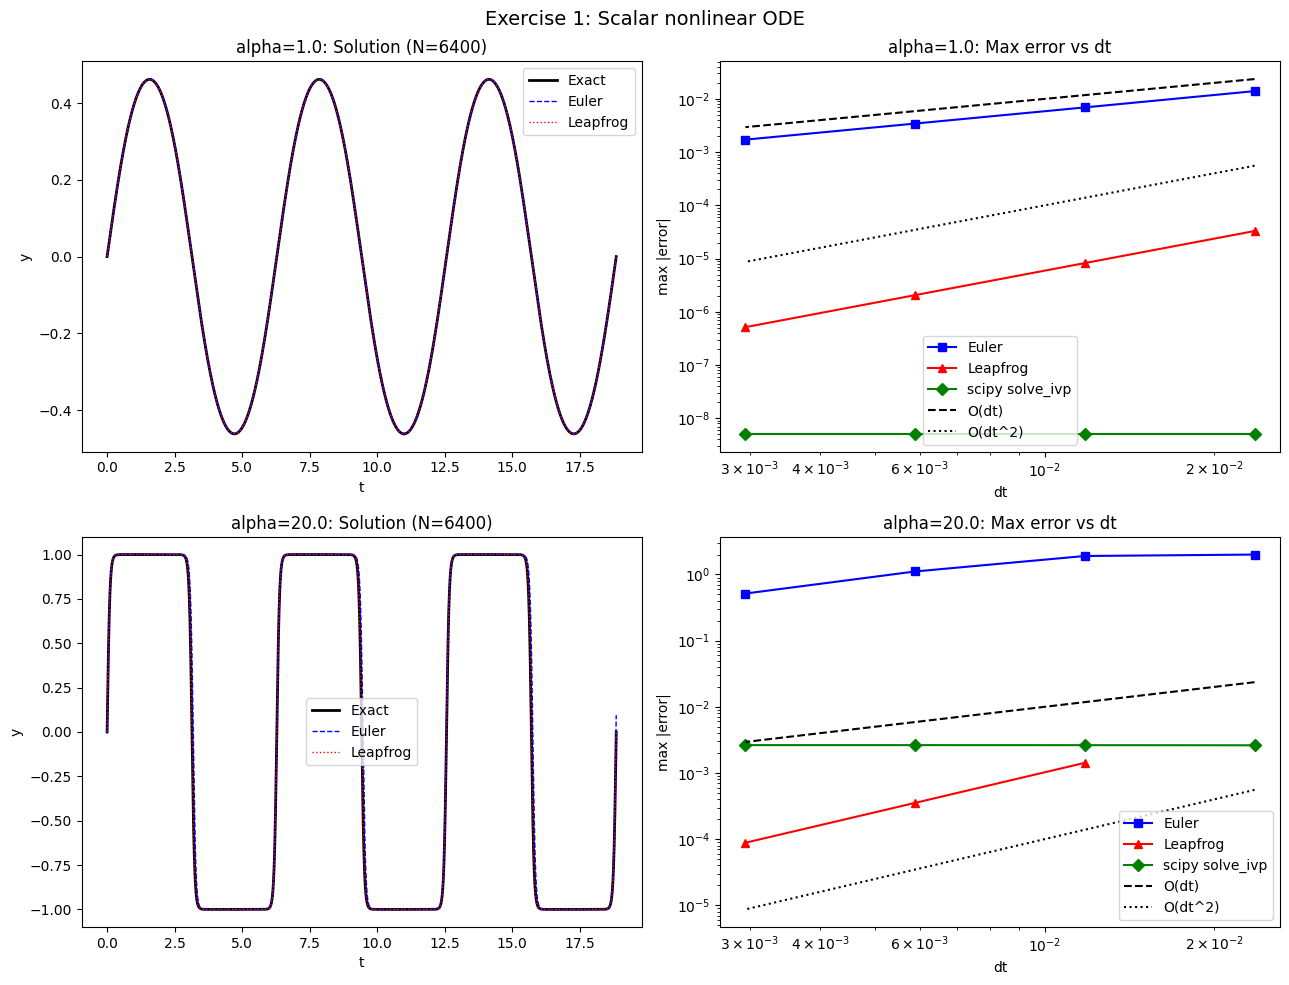

In [15]:
def f1(t, y, alpha):
    return (alpha / 2) * np.cos(t) * (1 - y**2)

def exact1(t, alpha):
    e = np.exp(alpha * np.sin(t))
    return (e - 1) / (e + 1)

def euler1(f, y0, T, N, alpha):
    dt = T / N
    t = np.linspace(0, T, N + 1)
    y = np.zeros(N + 1)
    y[0] = y0
    for n in range(N):
        y[n + 1] = y[n] + dt * f(t[n], y[n], alpha)
    return t, y

def leapfrog1(f, y0, T, N, alpha):
    """2-step leapfrog: y_{n+1} = y_{n-1} + 2*dt*f(t_n, y_n). Bootstrap step 1 with Euler."""
    dt = T / N
    t = np.linspace(0, T, N + 1)
    y = np.zeros(N + 1)
    y[0] = y0
    y[1] = y[0] + dt * f(t[0], y[0], alpha)
    for n in range(1, N):
        y[n + 1] = y[n - 1] + 2 * dt * f(t[n], y[n], alpha)
    return t, y

T1 = 6 * np.pi
y0_1 = 0.0
N_values = [800, 1600, 3200, 6400]

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
fig.suptitle('Exercise 1: Scalar nonlinear ODE', fontsize=14)

for idx, alpha in enumerate([1.0, 20.0]):
    ax_sol = axes[idx, 0]
    ax_err = axes[idx, 1]

    sol_ref = solve_ivp(lambda t, y: f1(t, y, alpha), [0, T1], [y0_1],
                        rtol=1e-10, atol=1e-12, dense_output=True)

    errors_euler, errors_lf, errors_scipy, dts = [], [], [], []
    for N in N_values:
        dt = T1 / N
        dts.append(dt)
        t_eval = np.linspace(0, T1, N + 1)
        y_ex = exact1(t_eval, alpha)
        _, y_eu = euler1(f1, y0_1, T1, N, alpha)
        _, y_lf = leapfrog1(f1, y0_1, T1, N, alpha)
        y_sp = sol_ref.sol(t_eval)
        errors_euler.append(np.max(np.abs(y_eu - y_ex)))
        errors_lf.append(np.max(np.abs(y_lf - y_ex)))
        errors_scipy.append(np.max(np.abs(y_sp - y_ex)))

    N_plot = 6400
    t_fine = np.linspace(0, T1, N_plot + 1)
    _, y_eu_plot = euler1(f1, y0_1, T1, N_plot, alpha)
    _, y_lf_plot = leapfrog1(f1, y0_1, T1, N_plot, alpha)
    y_exact_plot = exact1(t_fine, alpha)

    ax_sol.plot(t_fine, y_exact_plot, 'k-', label='Exact', lw=2)
    ax_sol.plot(t_fine, y_eu_plot, 'b--', label='Euler', lw=1)
    ax_sol.plot(t_fine, y_lf_plot, 'r:', label='Leapfrog', lw=1)
    ax_sol.set_title(f'alpha={alpha}: Solution (N={N_plot})')
    ax_sol.legend(); ax_sol.set_xlabel('t'); ax_sol.set_ylabel('y')

    dts = np.array(dts)
    ax_err.loglog(dts, errors_euler, 'bs-', label='Euler')
    ax_err.loglog(dts, errors_lf, 'r^-', label='Leapfrog')
    ax_err.loglog(dts, errors_scipy, 'gD-', label='scipy solve_ivp')
    ax_err.loglog(dts, dts, 'k--', label='O(dt)')
    ax_err.loglog(dts, dts**2, 'k:', label='O(dt^2)')
    ax_err.set_title(f'alpha={alpha}: Max error vs dt')
    ax_err.legend(); ax_err.set_xlabel('dt'); ax_err.set_ylabel('max |error|')

plt.tight_layout()
plt.show()

## Exercise 2
System: $y_1' = y_2$, $y_2' = -\frac{k}{m}y_1 - \frac{c}{m}y_2$ (damped harmonic oscillator)

Exact solution via `scipy.linalg.expm`. Methods: Explicit Euler, Implicit Euler (linear solve at each step).

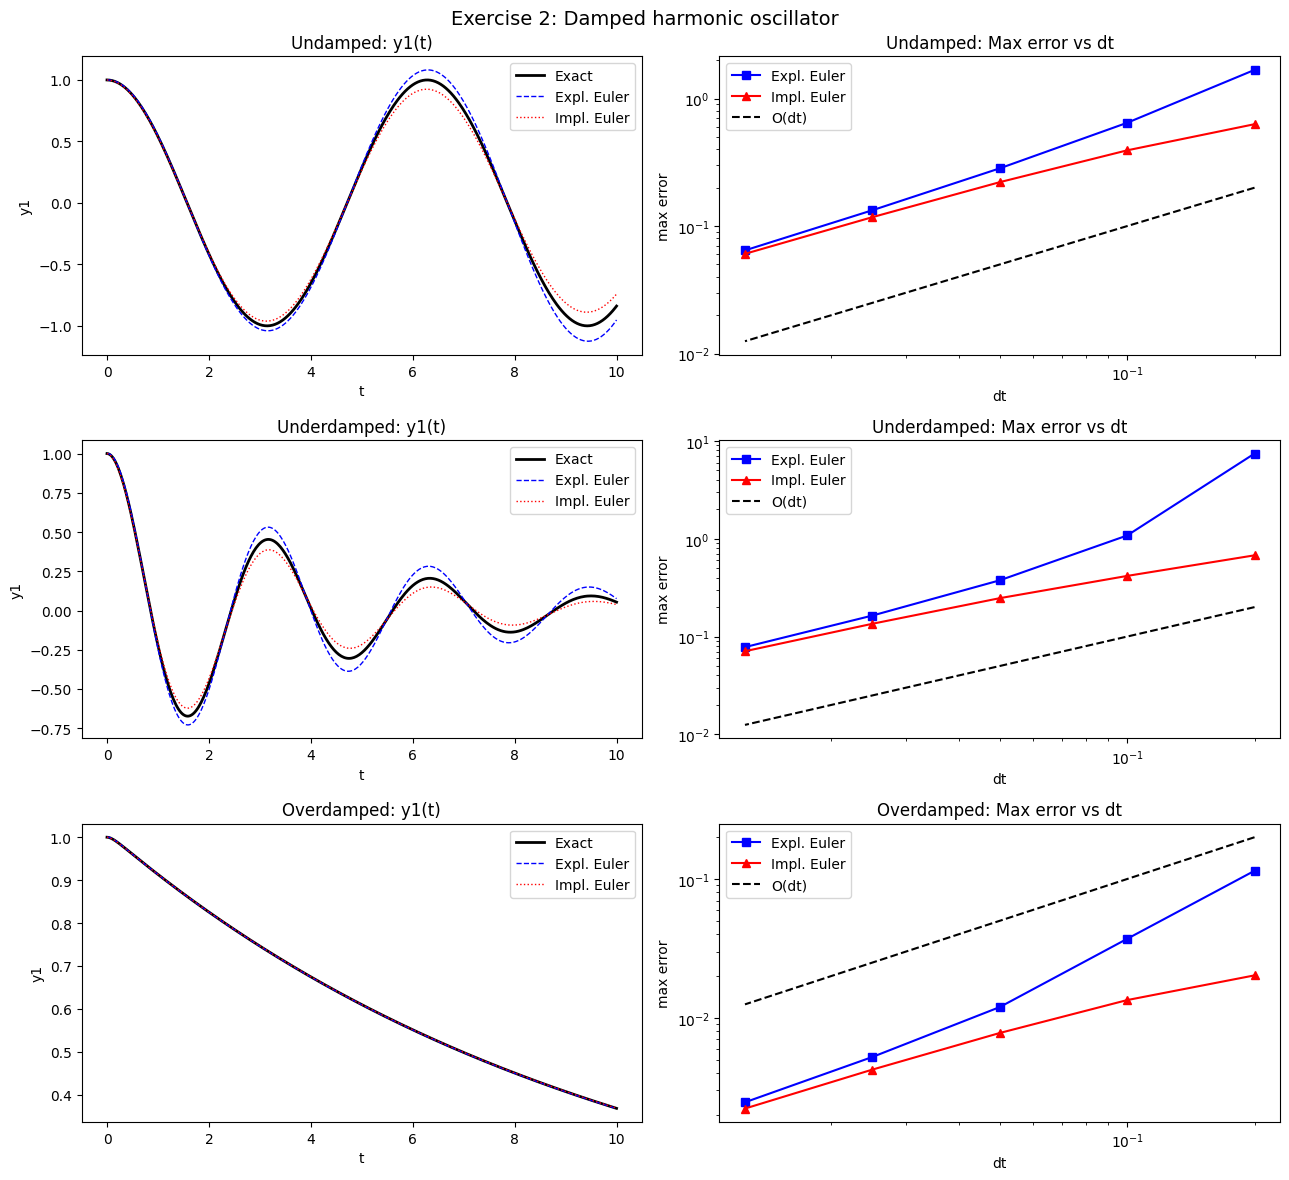

In [16]:
def make_A(k, m, c):
    return np.array([[0, 1], [-k/m, -c/m]])

def exact2(A, y0, t_eval):
    return np.array([expm(A * t) @ y0 for t in t_eval])

def euler2_explicit(A, y0, T, N):
    dt = T / N
    t = np.linspace(0, T, N + 1)
    y = np.zeros((N + 1, 2))
    y[0] = y0
    for n in range(N):
        y[n + 1] = y[n] + dt * (A @ y[n])
    return t, y

def euler2_implicit(A, y0, T, N):
    """Implicit Euler: (I - dt*A) y_{n+1} = y_n, solved with np.linalg.solve."""
    dt = T / N
    t = np.linspace(0, T, N + 1)
    y = np.zeros((N + 1, 2))
    y[0] = y0
    M = np.eye(2) - dt * A
    for n in range(N):
        y[n + 1] = np.linalg.solve(M, y[n])
    return t, y

cases = [
    dict(k=1.0, m=1.0, c=0.0,  y0=np.array([1.0, 0.0]), T=10.0, label='Undamped'),
    dict(k=4.0, m=1.0, c=0.5,  y0=np.array([1.0, 0.0]), T=10.0, label='Underdamped'),
    dict(k=1.0, m=1.0, c=10.0, y0=np.array([1.0, 0.0]), T=10.0, label='Overdamped'),
]

fig, axes = plt.subplots(len(cases), 2, figsize=(13, 4 * len(cases)))
fig.suptitle('Exercise 2: Damped harmonic oscillator', fontsize=14)

for row, case in enumerate(cases):
    A = make_A(case['k'], case['m'], case['c'])
    y0 = case['y0']
    T = case['T']
    N_values2 = [50, 100, 200, 400, 800]
    errors_ex, errors_im, dts = [], [], []

    for N in N_values2:
        dt = T / N
        t_eval = np.linspace(0, T, N + 1)
        y_ex_arr = exact2(A, y0, t_eval)
        _, y_eu = euler2_explicit(A, y0, T, N)
        _, y_im = euler2_implicit(A, y0, T, N)
        errors_ex.append(np.max(np.linalg.norm(y_eu - y_ex_arr, axis=1)))
        errors_im.append(np.max(np.linalg.norm(y_im - y_ex_arr, axis=1)))
        dts.append(dt)

    N_plot = 400
    t_plot = np.linspace(0, T, N_plot + 1)
    y_exact_plot = exact2(A, y0, t_plot)
    _, y_eu_plot = euler2_explicit(A, y0, T, N_plot)
    _, y_im_plot = euler2_implicit(A, y0, T, N_plot)

    ax_s = axes[row, 0]
    ax_s.plot(t_plot, y_exact_plot[:, 0], 'k-', label='Exact', lw=2)
    ax_s.plot(t_plot, y_eu_plot[:, 0], 'b--', label='Expl. Euler', lw=1)
    ax_s.plot(t_plot, y_im_plot[:, 0], 'r:', label='Impl. Euler', lw=1)
    ax_s.set_title(f"{case['label']}: y1(t)")
    ax_s.legend(); ax_s.set_xlabel('t'); ax_s.set_ylabel('y1')

    dts = np.array(dts)
    ax_e = axes[row, 1]
    ax_e.loglog(dts, errors_ex, 'bs-', label='Expl. Euler')
    ax_e.loglog(dts, errors_im, 'r^-', label='Impl. Euler')
    ax_e.loglog(dts, dts, 'k--', label='O(dt)')
    ax_e.set_title(f"{case['label']}: Max error vs dt")
    ax_e.legend(); ax_e.set_xlabel('dt'); ax_e.set_ylabel('max error')

plt.tight_layout()
plt.show()

## Exercise 3
Lorenz system with $\sigma=10$, $b=8/3$, $r=28$:
$$y_1' = -\sigma y_1 + \sigma y_2, \quad y_2' = r y_1 - y_2 - y_1 y_3, \quad y_3' = y_1 y_2 - b y_3$$

Reference via `solve_ivp` (tight tolerances). Methods: Explicit Euler, Leapfrog (bootstrapped from reference).

C:\Users\ismag\AppData\Local\Temp\ipykernel_28352\3199198904.py:5: RuntimeWarning: overflow encountered in scalar multiply
  r * y1 - y2 - y1 * y3,
C:\Users\ismag\AppData\Local\Temp\ipykernel_28352\3199198904.py:6: RuntimeWarning: overflow encountered in scalar multiply
  y1 * y2 - b * y3
C:\Users\ismag\AppData\Local\Temp\ipykernel_28352\3199198904.py:5: RuntimeWarning: invalid value encountered in scalar subtract
  r * y1 - y2 - y1 * y3,
C:\Users\ismag\AppData\Local\Temp\ipykernel_28352\3199198904.py:6: RuntimeWarning: invalid value encountered in scalar subtract
  y1 * y2 - b * y3


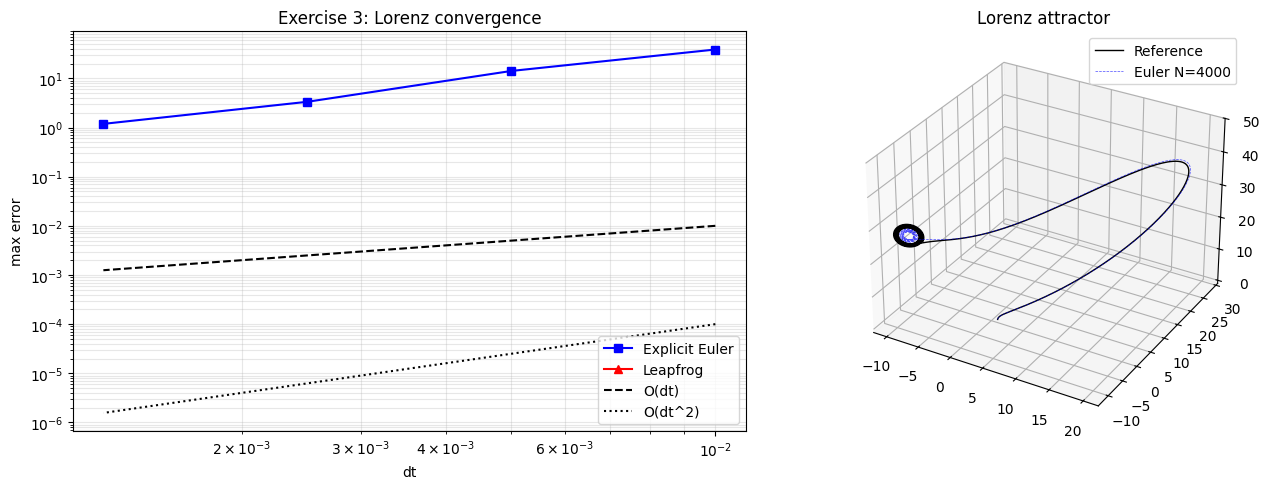

In [17]:
def lorenz(t, y, sigma=10, b=8/3, r=28):
    y1, y2, y3 = y
    return np.array([
        -sigma * y1 + sigma * y2,
        r * y1 - y2 - y1 * y3,
        y1 * y2 - b * y3
    ])

def euler_lorenz(y0, T, N):
    dt = T / N
    t = np.linspace(0, T, N + 1)
    y = np.zeros((N + 1, 3))
    y[0] = y0
    for i in range(N):
        y[i+1] = y[i] + dt * lorenz(t[i], y[i])
    return t, y

def leapfrog_lorenz(y0, y1_ref, T, N):
    """Leapfrog bootstrapped with reference solution at step 1."""
    dt = T / N
    t = np.linspace(0, T, N + 1)
    y = np.zeros((N + 1, 3))
    y[0] = y0
    y[1] = y1_ref
    for i in range(1, N):
        y[i+1] = y[i-1] + 2 * dt * lorenz(t[i], y[i])
    return t, y

y0_lorenz = np.array([1.0, 0.0, 0.0])
T_lorenz = 5.0

ref_sol = solve_ivp(lorenz, [0, T_lorenz], y0_lorenz, method='RK45',
                    rtol=1e-10, atol=1e-12, dense_output=True)

N_values3 = [500, 1000, 2000, 4000]
err_euler3, err_lf3, dts3 = [], [], []

for N in N_values3:
    dt = T_lorenz / N
    dts3.append(dt)
    t_eval = np.linspace(0, T_lorenz, N + 1)
    y_ref = ref_sol.sol(t_eval).T
    _, y_e = euler_lorenz(y0_lorenz, T_lorenz, N)
    _, y_l = leapfrog_lorenz(y0_lorenz, y_ref[1], T_lorenz, N)
    err_euler3.append(np.max(np.linalg.norm(y_e - y_ref, axis=1)))
    err_lf3.append(np.max(np.linalg.norm(y_l - y_ref, axis=1)))

dts3 = np.array(dts3)

fig = plt.figure(figsize=(14, 5))

ax1 = fig.add_subplot(1, 2, 1)
ax1.loglog(dts3, err_euler3, 'bs-', label='Explicit Euler')
ax1.loglog(dts3, err_lf3, 'r^-', label='Leapfrog')
ax1.loglog(dts3, dts3, 'k--', label='O(dt)')
ax1.loglog(dts3, dts3**2, 'k:', label='O(dt^2)')
ax1.set_xlabel('dt'); ax1.set_ylabel('max error')
ax1.set_title('Exercise 3: Lorenz convergence')
ax1.legend(); ax1.grid(True, which='both', alpha=0.3)

ax2 = fig.add_subplot(1, 2, 2, projection='3d')
N_plot = 4000
t_eval_plot = np.linspace(0, T_lorenz, N_plot + 1)
y_ref_plot = ref_sol.sol(t_eval_plot).T
_, y_e_plot = euler_lorenz(y0_lorenz, T_lorenz, N_plot)
ax2.plot(y_ref_plot[:,0], y_ref_plot[:,1], y_ref_plot[:,2], 'k', lw=1, label='Reference')
ax2.plot(y_e_plot[:,0], y_e_plot[:,1], y_e_plot[:,2], 'b--', lw=0.5, alpha=0.7, label='Euler N=4000')
ax2.set_title('Lorenz attractor')
ax2.legend()

plt.tight_layout()
plt.show()

## Exercise 4 â€” Advection-Diffusion (method of lines)
$$y_i' = -u\frac{y_{i+1}-y_{i-1}}{2\Delta x} + \nu\frac{y_{i+1}-2y_i+y_{i-1}}{\Delta x^2}, \quad i=2,\ldots,M-2$$
with $u=1$, $\nu=0.01$, $L=10$, $\Delta x = L/M$, $t\in[0,1]$.

Boundary rows use one-sided stencils (homogeneous Dirichlet BCs: $y_0=y_M=0$).
Methods: Explicit Euler, Implicit Euler. Exact via `expm`.

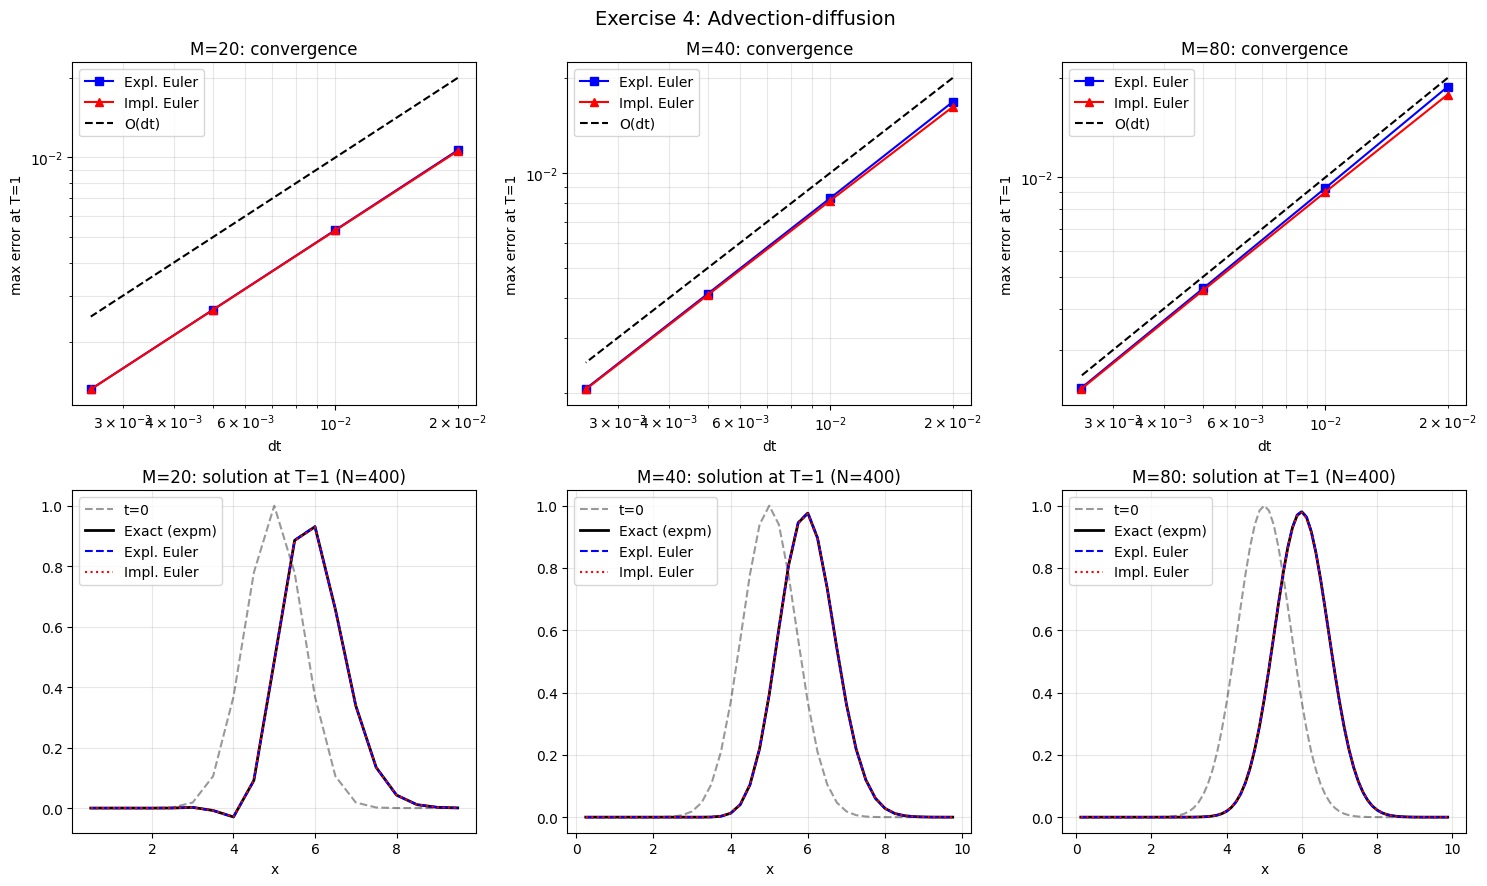

In [18]:
def build_adv_diff_matrix(M, u=1.0, nu=0.01, L=10.0):
    """Build (M-1)x(M-1) RHS matrix with homogeneous Dirichlet BCs."""
    dx = L / M
    n = M - 1
    A = np.zeros((n, n))
    adv = u / (2 * dx)
    diff = nu / dx**2
    for i in range(n):
        A[i, i] = -2 * diff
        if i > 0:
            A[i, i-1] = adv + diff
        if i < n - 1:
            A[i, i+1] = -adv + diff
    return A, dx

def initial_condition_ex4(M, L=10.0):
    dx = L / M
    x = np.arange(1, M) * dx
    return x, np.exp(-((x - 0.5*L) / (0.1*L))**2)

def euler_explicit_ex4(A, y0, T, N):
    dt = T / N
    y = np.zeros((N + 1, len(y0)))
    y[0] = y0
    for i in range(N):
        y[i+1] = y[i] + dt * (A @ y[i])
    return y

def euler_implicit_ex4(A, y0, T, N):
    """Implicit Euler: (I - dt*A) y^{n+1} = y^n, solved with np.linalg.solve."""
    dt = T / N
    n = len(y0)
    M_mat = np.eye(n) - dt * A
    y = np.zeros((N + 1, n))
    y[0] = y0
    for i in range(N):
        y[i+1] = np.linalg.solve(M_mat, y[i])
    return y

T_ex4 = 1.0
M_values = [20, 40, 80]
N_values4 = [50, 100, 200, 400]

fig, axes = plt.subplots(2, len(M_values), figsize=(15, 9))
fig.suptitle('Exercise 4: Advection-diffusion', fontsize=14)

for col, M in enumerate(M_values):
    A, dx = build_adv_diff_matrix(M)
    x, y0 = initial_condition_ex4(M)
    y_ex = expm(A * T_ex4) @ y0

    err_ee, err_ie, dts4 = [], [], []
    for N in N_values4:
        y_e = euler_explicit_ex4(A, y0, T_ex4, N)
        y_i = euler_implicit_ex4(A, y0, T_ex4, N)
        err_ee.append(np.max(np.abs(y_e[-1] - y_ex)))
        err_ie.append(np.max(np.abs(y_i[-1] - y_ex)))
        dts4.append(T_ex4 / N)

    dts4 = np.array(dts4)

    ax_e = axes[0, col]
    ax_e.loglog(dts4, err_ee, 'bs-', label='Expl. Euler')
    ax_e.loglog(dts4, err_ie, 'r^-', label='Impl. Euler')
    ax_e.loglog(dts4, dts4, 'k--', label='O(dt)')
    ax_e.set_xlabel('dt'); ax_e.set_ylabel('max error at T=1')
    ax_e.set_title(f'M={M}: convergence')
    ax_e.legend(); ax_e.grid(True, which='both', alpha=0.3)

    ax_s = axes[1, col]
    N_plot = 400
    y_e_plot = euler_explicit_ex4(A, y0, T_ex4, N_plot)
    y_i_plot = euler_implicit_ex4(A, y0, T_ex4, N_plot)
    ax_s.plot(x, y0, 'k--', alpha=0.4, label='t=0')
    ax_s.plot(x, y_ex, 'k', lw=2, label='Exact (expm)')
    ax_s.plot(x, y_e_plot[-1], 'b--', label='Expl. Euler')
    ax_s.plot(x, y_i_plot[-1], 'r:', label='Impl. Euler')
    ax_s.set_title(f'M={M}: solution at T=1 (N={N_plot})')
    ax_s.set_xlabel('x'); ax_s.legend(); ax_s.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()